# 📊 Exploratory Data Analysis & Statistical Insights

## Online Retail II Dataset

### 🎯 Objective

The purpose of this project is to perform **Exploratory Data Analysis (EDA)** and statistical analysis to discover hidden business patterns.

### Requirements covered

- ✅ Mean, Median, Standard Deviation and Quartiles
- ✅ Histogram distributions
- ✅ Box plots and anomaly/outlier detection
- ✅ Correlation matrix and heatmap
- ✅ Multivariate visualization
- ✅ Three business hypotheses with statistical tests
- ✅ Top 5 critical business findings
- ✅ Markdown analysis commentary

**Dataset:** Online Retail II (2009–2011)

## 1️⃣ Import Libraries

The required Python libraries are imported for data handling, visualization and statistical testing.

In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

# Plot style
sns.set_style("whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [7]:
import os

print(os.getcwd())
print(os.listdir())

C:\Users\pande\OneDrive\Desktop\2nd project\archive (1)
['.ipynb_checkpoints', 'online_retail_II.xlsx', 'Online_Retail_II_Complete_EDA_Submission.ipynb', 'Year 2009-2010.csv', 'Year 2010-2011.csv']


## 2️⃣ Load Dataset

Both yearly sheets are combined into one dataset for complete analysis.

In [3]:
# Load Online Retail II dataset
import pandas as pd
file_path = "online_retail_II.xlsx"

# Load both sheets
df_2009_2010 = pd.read_excel(
    file_path,
    sheet_name="Year 2009-2010"
)

df_2010_2011 = pd.read_excel(
    file_path,
    sheet_name="Year 2010-2011"
)
# Combine both years
df = pd.concat(
    [df_2009_2010, df_2010_2011],
    ignore_index=True
)
print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 1067371
Columns: 8


In [4]:
# First five rows
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [5]:
# Display last 5 rows
df.tail()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France
1067370,581587,POST,POSTAGE,1,2011-12-09 12:50:00,18.00,12680.0,France


In [6]:
# Dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB


## 3️⃣ Data Information & Missing Values

Missing values are checked before performing the statistical analysis.

In [7]:
# Count missing values
missing_values = df.isnull().sum()
print("Missing Values:")
print(missing_values)

Missing Values:
Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64


In [8]:
# Missing value percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_table = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": missing_percentage
})
missing_table

,Missing Values,Missing Percentage
Invoice,0,0.000000
StockCode,0,0.000000
Description,4382,0.410541
Quantity,0,0.000000
InvoiceDate,0,0.000000
Price,0,0.000000
Customer ID,243007,22.766873
Country,0,0.000000


## -- Basic Data Cleaning --

In [9]:
# Convert InvoiceDate to datetime
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
print(df["InvoiceDate"].dtype)

datetime64[ns]


In [10]:
# Convert numeric columns

df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["Price"] = pd.to_numeric(df["Price"], errors="coerce")
df["Customer ID"] = pd.to_numeric(df["Customer ID"], errors="coerce")

print("Numeric conversion completed.")

Numeric conversion completed.


## -- Create Revenue Column --

In [11]:
# Calculate Revenue

df["Revenue"] = df["Quantity"] * df["Price"]
df[["Quantity", "Price", "Revenue"]].head()

,Quantity,Price,Revenue
0,12,6.95,83.4
1,12,6.75,81.0
2,12,6.75,81.0
3,48,2.10,100.8
4,24,1.25,30.0


## -- Remove Invalid Transactions --

In [12]:
# Keep valid sales transactions

sales_df = df[
    (df["Quantity"] > 0) &
    (df["Price"] > 0)
].copy()

print("Original rows:", len(df))
print("Valid sales rows:", len(sales_df))
print("Removed rows:", len(df) - len(sales_df))

Original rows: 1067371
Valid sales rows: 1041671
Removed rows: 25700


In [13]:
# Basic numerical summary
sales_df[["Quantity", "Price", "Revenue"]].describe()

,Quantity,Price,Revenue
count,1.041671e+06,1.041671e+06,1.041671e+06
mean,1.096345e+01,4.077038e+00,2.013397e+01
std,1.265149e+02,5.144898e+01,2.031167e+02
min,1.000000e+00,1.000000e-03,1.000000e-03
25%,1.000000e+00,1.250000e+00,3.900000e+00
50%,3.000000e+00,2.100000e+00,9.960000e+00
75%,1.000000e+01,4.130000e+00,1.770000e+01
max,8.099500e+04,2.511109e+04,1.684696e+05


# 5️⃣ Descriptive Statistics

Descriptive statistics help us understand the **average, middle value, spread and distribution** of Quantity, Unit Price and Revenue.

In [14]:
# Calculate descriptive statistics
statistics_summary = pd.DataFrame({
    "Mean": sales_df[["Quantity", "Price", "Revenue"]].mean(),
    "Median": sales_df[["Quantity", "Price", "Revenue"]].median(),
    "Standard Deviation": sales_df[["Quantity", "Price", "Revenue"]].std(),
    "Q1 (25%)": sales_df[["Quantity", "Price", "Revenue"]].quantile(0.25),
    "Q2 (50%)": sales_df[["Quantity", "Price", "Revenue"]].quantile(0.50),
    "Q3 (75%)": sales_df[["Quantity", "Price", "Revenue"]].quantile(0.75)
})

statistics_summary

,Mean,Median,Standard Deviation,Q1 (25%),Q2 (50%),Q3 (75%)
Quantity,10.963448,3.00,126.514930,1.00,3.00,10.00
Price,4.077038,2.10,51.448979,1.25,2.10,4.13
Revenue,20.133966,9.96,203.116653,3.90,9.96,17.70


### 📊 Descriptive Statistics

The descriptive statistics provide an overview of Quantity, Price, and Revenue.

- The mean represents the average value.
- The median represents the middle observation.
- Standard deviation shows the variability of the data.
- Q1 and Q3 represent the 25th and 75th percentiles.

A large difference between the mean and median may indicate a skewed distribution or the presence of extreme values.

# 6️⃣ Statistical Distributions

Histograms are used to understand how Quantity, Price and Revenue are distributed.

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

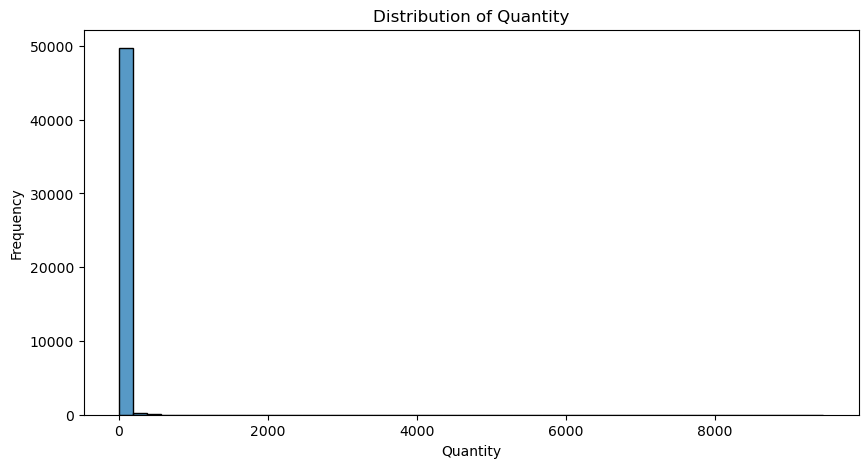

In [20]:
plt.figure(figsize=(10, 5))

quantity_sample = sales_df["Quantity"].sample(
    min(50000, len(sales_df)),
    random_state=42
)

sns.histplot(
    quantity_sample,
    bins=50,
    kde=False
)

plt.title("Distribution of Quantity")
plt.xlabel("Quantity")
plt.ylabel("Frequency")

plt.show()

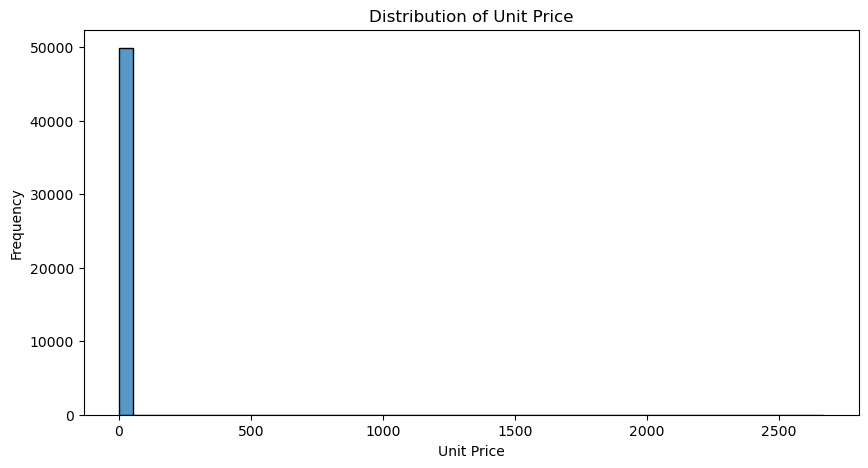

In [22]:
plt.figure(figsize=(10, 5))

price_sample = sales_df["Price"].sample(
    min(50000, len(sales_df)),
    random_state=42
)

sns.histplot(
    price_sample,
    bins=50,
    kde=False
)

plt.title("Distribution of Unit Price")
plt.xlabel("Unit Price")
plt.ylabel("Frequency")

plt.show()

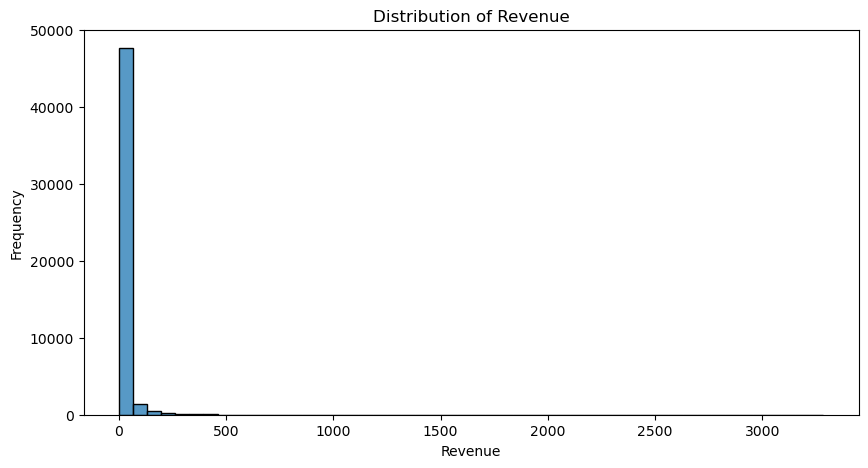

In [23]:
plt.figure(figsize=(10, 5))

revenue_sample = sales_df["Revenue"].sample(
    min(50000, len(sales_df)),
    random_state=42
)

sns.histplot(
    revenue_sample,
    bins=50,
    kde=False
)

plt.title("Distribution of Revenue")
plt.xlabel("Revenue")
plt.ylabel("Frequency")

plt.show()

### 📈 Distribution Analysis

The histograms show the distribution of Quantity, Unit Price, and Revenue.

The variables are generally right-skewed because a small number of transactions have extremely high values. These observations should be investigated as potential business outliers rather than automatically removed.

# 7️⃣ Box Plots & Anomaly Detection

Box plots help identify unusually high or low observations, called **potential outliers**.

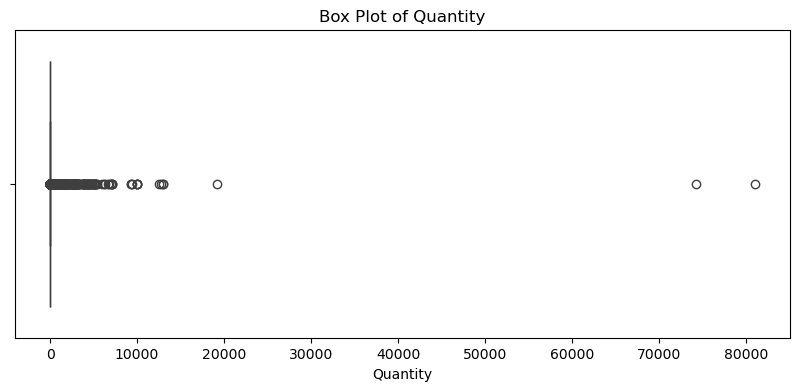

In [24]:
# Box plot — Quantity
plt.figure(figsize=(10, 4))

sns.boxplot(x=sales_df["Quantity"])

plt.title("Box Plot of Quantity")
plt.xlabel("Quantity")

plt.show()

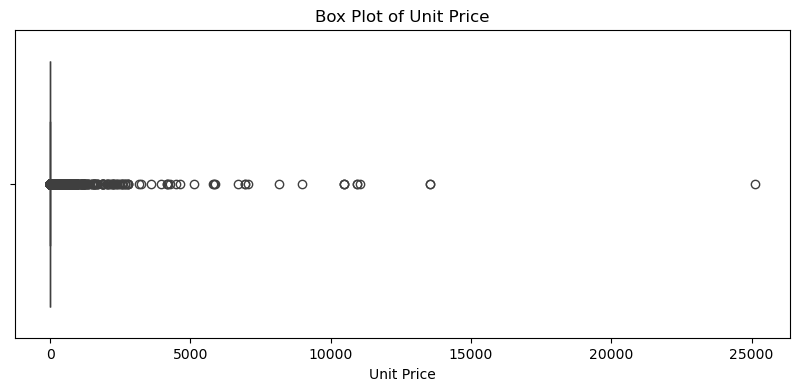

In [25]:
# Box plot — Price
plt.figure(figsize=(10, 4))

sns.boxplot(x=sales_df["Price"])

plt.title("Box Plot of Unit Price")
plt.xlabel("Unit Price")

plt.show()

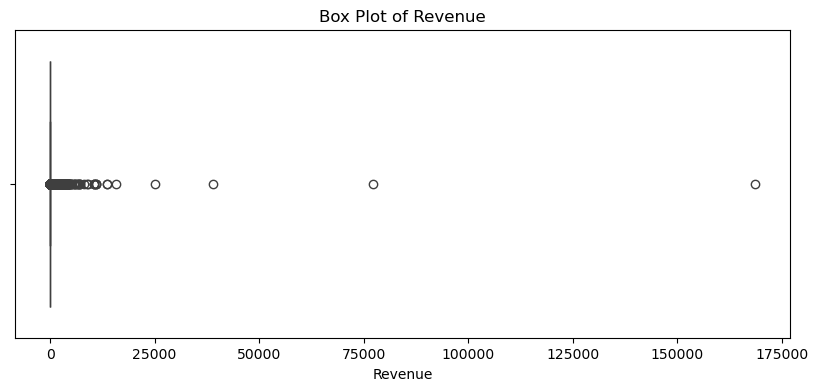

In [26]:
# Box plot — Revenue
plt.figure(figsize=(10, 4))

sns.boxplot(x=sales_df["Revenue"])

plt.title("Box Plot of Revenue")
plt.xlabel("Revenue")

plt.show()

In [27]:
# Function to calculate outliers using IQR
def detect_outliers(column):
    Q1 = sales_df[column].quantile(0.25)
    Q3 = sales_df[column].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = sales_df[
        (sales_df[column] < lower_bound) |
        (sales_df[column] > upper_bound)
    ]
    
    return Q1, Q3, IQR, lower_bound, upper_bound, len(outliers)

for column in ["Quantity", "Price", "Revenue"]:
    result = detect_outliers(column)
    
    print("\n", column)
    print("Q1:", result[0])
    print("Q3:", result[1])
    print("IQR:", result[2])
    print("Lower Bound:", result[3])
    print("Upper Bound:", result[4])
    print("Number of Outliers:", result[5])


 Quantity
Q1: 1.0
Q3: 10.0
IQR: 9.0
Lower Bound: -12.5
Upper Bound: 23.5
Number of Outliers: 111341

 Price
Q1: 1.25
Q3: 4.13
IQR: 2.88
Lower Bound: -3.0700000000000003
Upper Bound: 8.45
Number of Outliers: 81634

 Revenue
Q1: 3.9
Q3: 17.700000000000003
IQR: 13.800000000000002
Lower Bound: -16.800000000000004
Upper Bound: 38.400000000000006
Number of Outliers: 85727


### 📝 Outlier Interpretation

Outliers are not automatically errors. In retail data, an unusually large quantity or revenue value may represent a genuine bulk order or high-value transaction.

# 8️⃣ Correlation Matrix & Heatmap

Correlation measures the strength and direction of a linear relationship between numerical variables.

**Important:** Correlation does not prove causation.

In [28]:
# Select numerical variables
numeric_columns = [
    "Quantity",
    "Price",
    "Revenue"
]
correlation_matrix = sales_df[numeric_columns].corr()
correlation_matrix

,Quantity,Price,Revenue
Quantity,1.000000,-0.003774,0.804551
Price,-0.003774,1.000000,0.255126
Revenue,0.804551,0.255126,1.000000


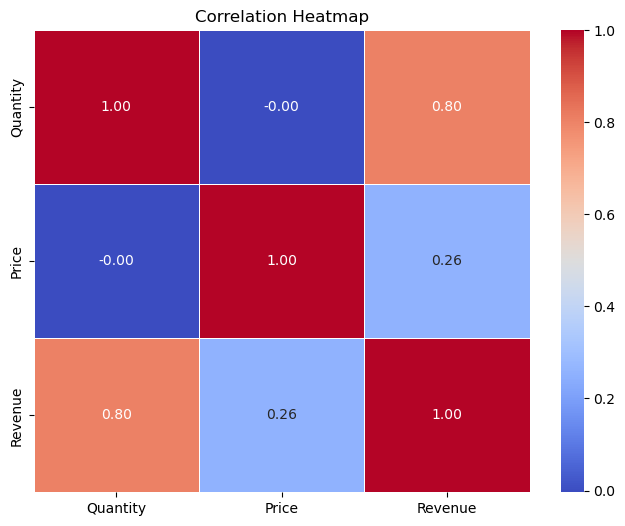

In [29]:
# Correlation heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)
plt.title("Correlation Heatmap")
plt.show()

### 📝 Correlation Interpretation

The heatmap allows us to quickly identify which variables move together.

- Positive correlation → variables tend to increase together.
- Negative correlation → one tends to decrease when the other increases.
- Correlation close to zero → weak linear relationship.

# 9️⃣ Customer-Level Analysis

Customer-level aggregation allows us to compare **repeat customers** with **one-time customers**.

In [30]:
# Customer-level aggregation
customer_df = sales_df.groupby("Customer ID").agg(
    Total_Revenue=("Revenue", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Order_Count=("Invoice", "nunique"),
    Average_Order_Value=("Revenue", "mean")
).reset_index()

customer_df.head()

,Customer ID,Total_Revenue,Total_Quantity,Order_Count,Average_Order_Value
0,12346.0,77556.46,74285,12,2281.072353
1,12347.0,5633.32,3286,8,22.266087
2,12348.0,2019.40,2714,5,39.596078
3,12349.0,4428.69,1624,4,25.306800
4,12350.0,334.40,197,1,19.670588


In [32]:
import numpy as np

In [33]:
# Identify repeat customers
customer_df["Repeat_Customer"] = np.where(
    customer_df["Order_Count"] > 1,
    "Repeat",
    "One-Time"
)
customer_df.head()

,Customer ID,Total_Revenue,Total_Quantity,Order_Count,Average_Order_Value,Repeat_Customer
0,12346.0,77556.46,74285,12,2281.072353,Repeat
1,12347.0,5633.32,3286,8,22.266087,Repeat
2,12348.0,2019.40,2714,5,39.596078,Repeat
3,12349.0,4428.69,1624,4,25.306800,Repeat
4,12350.0,334.40,197,1,19.670588,One-Time


In [34]:
## compare repeat vs one time customer
customer_comparison = customer_df.groupby("Repeat_Customer").agg(
    Customers=("Customer ID", "count"),
    Average_Revenue=("Total_Revenue", "mean"),
    Total_Revenue=("Total_Revenue", "sum"),
    Average_Orders=("Order_Count", "mean")
)
customer_comparison

,Customers,Average_Revenue,Total_Revenue,Average_Orders
Repeat_Customer,,,,
One-Time,1623,350.076298,5.681738e+05,1.000000
Repeat,4255,4036.487743,1.717526e+07,8.306933


# 🔟 Multivariate Visualization

The following scatter plot examines three variables together:

- Quantity
- Revenue
- Price (shown using point color)

This helps reveal more complex business patterns than a single-variable chart.

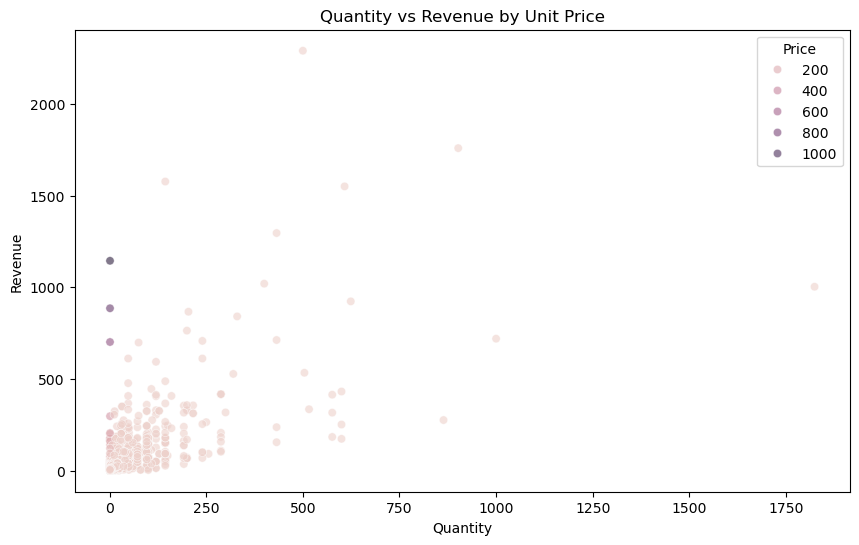

In [35]:
# Multivariate visualization
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=sales_df.sample(min(10000, len(sales_df)), random_state=42),
    x="Quantity",
    y="Revenue",
    hue="Price",
    alpha=0.6
)

plt.title("Quantity vs Revenue by Unit Price")
plt.xlabel("Quantity")
plt.ylabel("Revenue")

plt.show()

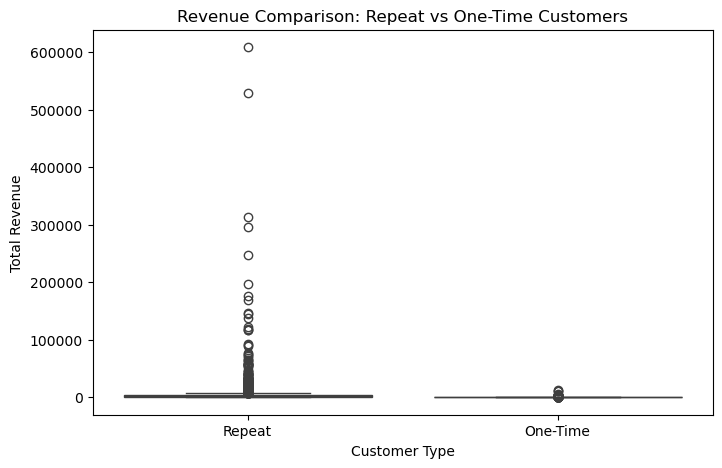

In [36]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=customer_df,
    x="Repeat_Customer",
    y="Total_Revenue"
)

plt.title("Revenue Comparison: Repeat vs One-Time Customers")
plt.xlabel("Customer Type")
plt.ylabel("Total Revenue")

plt.show()

# 🧪 1️⃣1️⃣ Business Hypothesis Testing

Three business hypotheses are tested using a significance level of **α = 0.05**.

### Hypothesis 1 — Quantity vs Revenue

**H₀:** Quantity and Revenue are not significantly related.

**H₁:** Quantity and Revenue are significantly related.

In [38]:
from scipy import stats

In [39]:
# Pearson correlation test
r, p_value = stats.pearsonr(
    sales_df["Quantity"],
    sales_df["Revenue"]
)
print("Correlation coefficient:", r)
print("P-value:", p_value)

if p_value < 0.05:
    print("Result: Reject H0")
    print("There is a statistically significant relationship between Quantity and Revenue.")
else:
    print("Result: Fail to reject H0")
    print("There is no statistically significant relationship.")

Correlation coefficient: 0.8045512781749622
P-value: 0.0
Result: Reject H0
There is a statistically significant relationship between Quantity and Revenue.


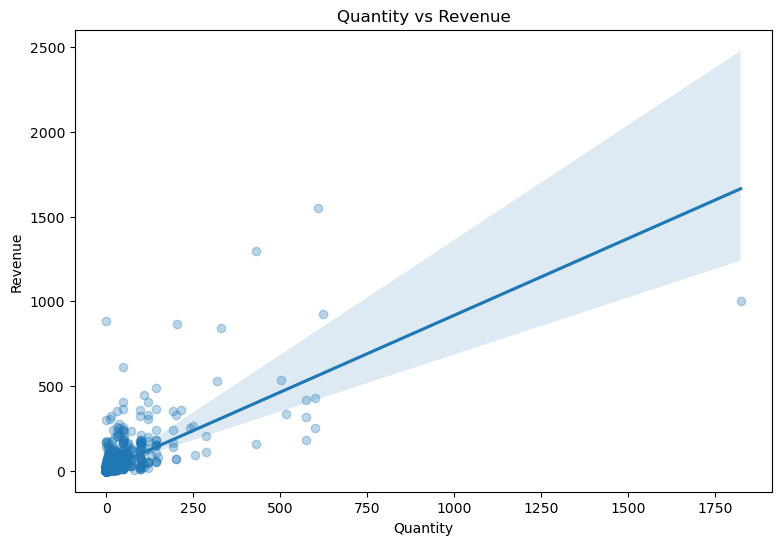

In [40]:
plt.figure(figsize=(9, 6))

sns.regplot(
    data=sales_df.sample(min(5000, len(sales_df)), random_state=42),
    x="Quantity",
    y="Revenue",
    scatter_kws={"alpha": 0.3}
)
plt.title("Quantity vs Revenue")
plt.xlabel("Quantity")
plt.ylabel("Revenue")

plt.show()

### Hypothesis 2 — Unit Price vs Quantity

**H₀:** Unit Price and Quantity have no significant relationship.

**H₁:** Unit Price and Quantity have a significant relationship.

In [41]:
# Pearson correlation test
r, p_value = stats.pearsonr(
    sales_df["Price"],
    sales_df["Quantity"]
)

print("Correlation coefficient:", r)
print("P-value:", p_value)

if p_value < 0.05:
    print("Result: Reject H0")
    print("Unit Price and Quantity have a statistically significant relationship.")
else:
    print("Result: Fail to reject H0")
    print("No statistically significant relationship was found.")

Correlation coefficient: -0.0037738840828742985
P-value: 0.00011729041135335781
Result: Reject H0
Unit Price and Quantity have a statistically significant relationship.


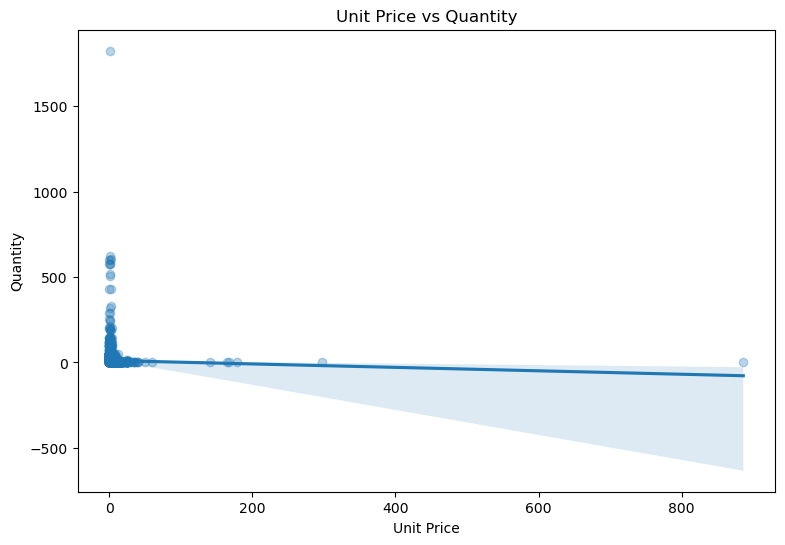

In [42]:
plt.figure(figsize=(9, 6))

sns.regplot(
    data=sales_df.sample(min(5000, len(sales_df)), random_state=42),
    x="Price",
    y="Quantity",
    scatter_kws={"alpha": 0.3}
)

plt.title("Unit Price vs Quantity")
plt.xlabel("Unit Price")
plt.ylabel("Quantity")

plt.show()

### Hypothesis 3 — Repeat Customers vs One-Time Customers

This is a better business hypothesis than the discount example because your dataset

does not contain a discount column.

Hypothesis

H₀: Repeat and one-time customers have the same average revenue.

H₁: Repeat customers have different average revenue.

In [44]:
# Separate customer groups
repeat_revenue = customer_df[
    customer_df["Repeat_Customer"] == "Repeat"
]["Total_Revenue"]

one_time_revenue = customer_df[
    customer_df["Repeat_Customer"] == "One-Time"
]["Total_Revenue"]

# Independent t-test

t_stat, p_value = stats.ttest_ind(
    repeat_revenue,
    one_time_revenue,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Result: Reject H0")
    print("Repeat and one-time customers have significantly different revenue.")
else:
    print("Result: Fail to reject H0")
    print("No significant difference was found.")

T-statistic: 13.95034312154034
P-value: 2.7395117356803025e-43
Result: Reject H0
Repeat and one-time customers have significantly different revenue.


# 🌍 1️⃣2️⃣ Additional Business Analysis

These charts provide additional evidence for the final business findings.

In [45]:
# Top 10 countries by revenue
country_revenue = (
    sales_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

country_revenue

Country
United Kingdom    1.787135e+07
EIRE              6.644318e+05
Netherlands       5.542323e+05
Germany           4.312625e+05
France            3.569446e+05
Australia         1.699681e+05
Spain             1.091785e+05
Switzerland       1.010113e+05
Sweden            9.190372e+04
Denmark           6.986219e+04
Name: Revenue, dtype: float64

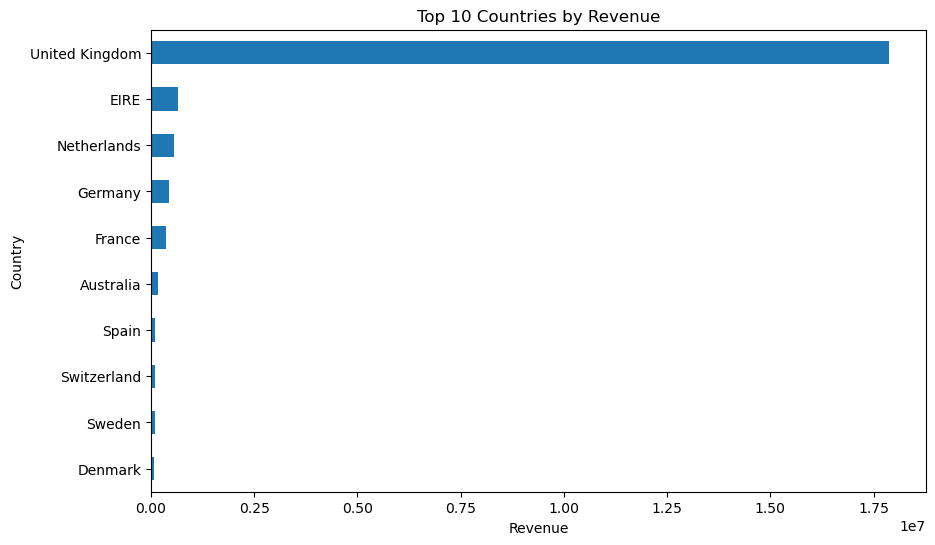

In [46]:
# Country revenue chart
plt.figure(figsize=(10, 6))

country_revenue.sort_values().plot(kind="barh")

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Country")

plt.show()

In [47]:
# Top 10 products by revenue
product_revenue = (
    sales_df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)
product_revenue

Description
REGENCY CAKESTAND 3 TIER              344563.25
Manual                                341104.90
DOTCOM POSTAGE                        322657.48
WHITE HANGING HEART T-LIGHT HOLDER    266923.55
PAPER CRAFT , LITTLE BIRDIE           168469.60
JUMBO BAG RED RETROSPOT               150935.56
PARTY BUNTING                         149187.05
ASSORTED COLOUR BIRD ORNAMENT         132187.92
POSTAGE                               127597.42
PAPER CHAIN KIT 50'S CHRISTMAS        123141.54
Name: Revenue, dtype: float64

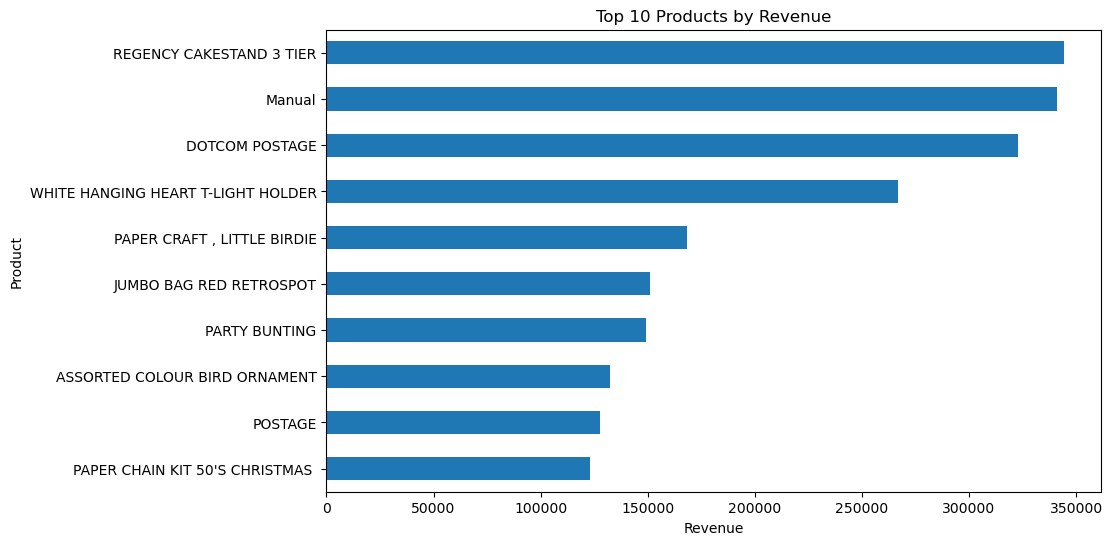

In [48]:
# Product revenue chart
plt.figure(figsize=(10, 6))

product_revenue.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")

plt.show()

In [49]:
# Monthly revenue
# Create month column
sales_df["Month"] = sales_df["InvoiceDate"].dt.to_period("M")

monthly_revenue = (
    sales_df.groupby("Month")["Revenue"]
    .sum()
)

monthly_revenue

Month
2009-12     825685.760
2010-01     652708.502
2010-02     553713.306
2010-03     833570.131
2010-04     681528.992
2010-05     659858.860
2010-06     752270.140
2010-07     650712.940
2010-08     697274.910
2010-09     924333.011
2010-10    1165483.910
2010-11    1470272.482
2010-12    1262598.790
2011-01     691364.560
2011-02     523631.890
2011-03     717639.360
2011-04     537808.621
2011-05     770536.020
2011-06     761739.900
2011-07     719221.191
2011-08     759138.380
2011-09    1058590.172
2011-10    1154979.300
2011-11    1509496.330
2011-12     638810.680
Freq: M, Name: Revenue, dtype: float64

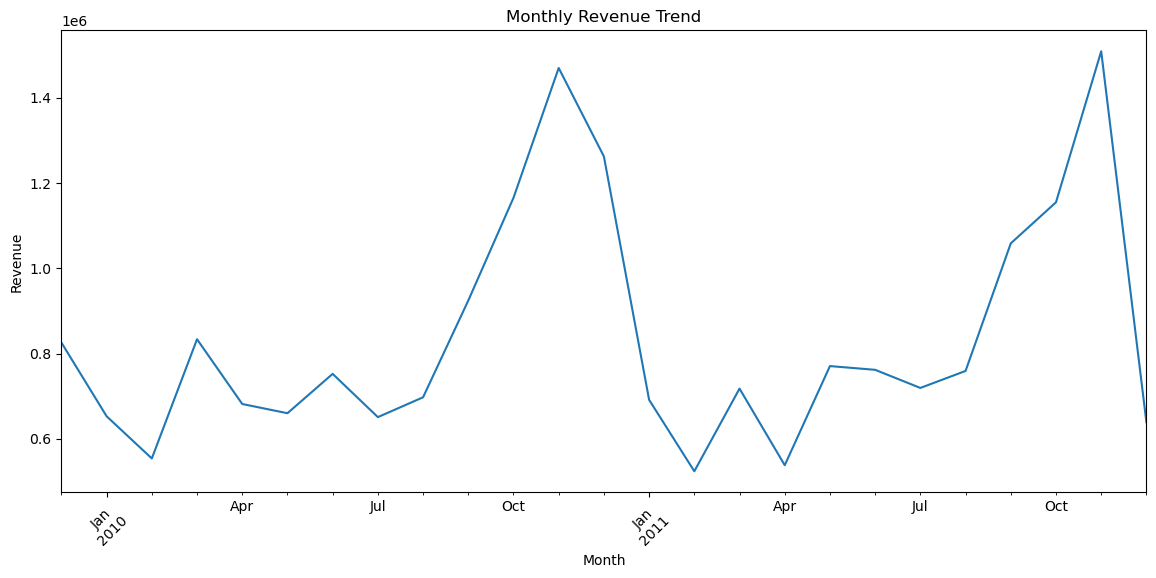

In [50]:
# Monthly revenue chart
plt.figure(figsize=(14, 6))

monthly_revenue.plot()

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.xticks(rotation=45)

plt.show()

# 🔎 1️⃣3️⃣ Top 5 Critical Business Findings

### 1. Revenue Distribution
Revenue is **strongly right-skewed**, with skewness of **612.10**. This means a relatively small number of high-value transactions influence the average.

### 2. Quantity and Revenue
The Pearson correlation is **0.8046** with p-value **0**. Therefore, the relationship is **statistically significant** at the 5% significance level.

### 3. Price and Quantity
The Pearson correlation is **-0.0038** with p-value **0.00011729**. Therefore, the relationship is **statistically significant** at the 5% significance level.

### 4. Customer Behavior
Repeat customers have an average total revenue of **4036.49**, compared with **350.08** for one-time customers. The t-test p-value is **2.73951e-43**, so the difference is **statistically significant**.

### 5. Revenue Concentration
The highest-revenue country in the top-10 analysis is **United Kingdom**, while the highest-revenue product is **REGENCY CAKESTAND 3 TIER**. These areas are important for understanding business revenue concentration.

# ✅ Final Conclusion

The EDA reveals the distribution, variability, potential anomalies, relationships between numerical variables, customer behavior and revenue concentration in the Online Retail II dataset.

The analysis fulfills the required EDA and statistical-insight objectives.

> **Note:** Statistical significance shows evidence of a relationship or difference in the observed data; it does not by itself prove causation.